# Car Price Prediction with Machine Learning
**Oasis Infobyte Internship · Python Track · Task 3**

**Objective:** Build regression models that predict the selling price of a used car from features such as brand, age, mileage, fuel type and transmission.

**Dataset:** "Vehicle dataset from CarDekho" on Kaggle (file usually named `CAR DETAILS FROM CAR DEKHO.csv`, with columns `name, year, selling_price, km_driven, fuel, seller_type, transmission, owner`). Prices are in Indian Rupees (₹).

**Before running:** place the CSV in the same folder as this notebook and check the file name in Section 2.

**Workflow:** Load → Clean → Feature engineering → EDA → Encode → Correlation → Split → Train 3 models → Evaluate → Feature importance

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load the Data

In [2]:
CSV_PATH = "CAR DETAILS FROM CAR DEKHO.csv"   # change this if your downloaded file has a different name

raw = pd.read_csv(CSV_PATH)
df = raw.copy()

# Tidy the column names: lowercase, no stray spaces
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
df = df.rename(columns={"car_name": "name", "kms_driven": "km_driven", "fuel_type": "fuel"})

# Some versions of the dataset include the price of the car when new. It is not one of the
# task's features, so it is dropped to keep the analysis consistent.
df = df.drop(columns=[c for c in ["present_price"] if c in df.columns])

required = ["name", "year", "selling_price", "km_driven", "fuel", "transmission"]
missing = [c for c in required if c not in df.columns]
assert not missing, f"These required columns are missing from your file: {missing}. Found: {list(df.columns)}"

df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


## 3. Data Cleaning

### 3.1 Inspect shape, types, nulls and duplicates

In [3]:
print("Shape (rows, columns):", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nNull values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Shape (rows, columns): (4340, 8)

Data types:
name               str
year             int64
selling_price    int64
km_driven        int64
fuel               str
seller_type        str
transmission       str
owner              str
dtype: object

Null values per column:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Duplicate rows: 763


### 3.2 Handle nulls, duplicates and inconsistent categories

In [4]:
categorical = [c for c in ["fuel", "seller_type", "transmission", "owner"] if c in df.columns]

print("Unique values BEFORE cleaning:")
for c in categorical:
    print(f"  {c}: {sorted(df[c].dropna().astype(str).unique())}")

# 1) Drop rows with missing values in the columns we need
before = len(df)
df = df.dropna(subset=required)

# 2) Make text consistent: strip spaces and use one capitalisation ("petrol " -> "Petrol")
for c in ["name"] + categorical:
    df[c] = df[c].astype(str).str.strip()
for c in categorical:
    df[c] = df[c].str.title()

# 3) Remove duplicate rows and impossible values
df = df.drop_duplicates()
df = df[(df["selling_price"] > 0) & (df["km_driven"] >= 0)].reset_index(drop=True)

print(f"\nRows removed in cleaning: {before - len(df)}  (remaining: {len(df)})")
print("\nUnique values AFTER cleaning:")
for c in categorical:
    print(f"  {c}: {sorted(df[c].unique())}")

Unique values BEFORE cleaning:
  fuel: ['CNG', 'Diesel', 'Electric', 'LPG', 'Petrol']
  seller_type: ['Dealer', 'Individual', 'Trustmark Dealer']
  transmission: ['Automatic', 'Manual']
  owner: ['First Owner', 'Fourth & Above Owner', 'Second Owner', 'Test Drive Car', 'Third Owner']

Rows removed in cleaning: 763  (remaining: 3577)

Unique values AFTER cleaning:
  fuel: ['Cng', 'Diesel', 'Electric', 'Lpg', 'Petrol']
  seller_type: ['Dealer', 'Individual', 'Trustmark Dealer']
  transmission: ['Automatic', 'Manual']
  owner: ['First Owner', 'Fourth & Above Owner', 'Second Owner', 'Test Drive Car', 'Third Owner']


**Observations:** Categorical columns are now consistent, with no case or spacing variants of the same value. Duplicate rows were removed, because repeated listings would let the model "see" the same car in both the training and test sets and make the scores look better than they are.

## 4. Feature Engineering

In [5]:
# Car age: measured from the year after the newest model year in the data (keeps results reproducible)
REFERENCE_YEAR = int(df["year"].max()) + 1
df["car_age"] = REFERENCE_YEAR - df["year"]

# Brand: the first word of the car name (a few brands have two-word names)
def get_brand(name):
    brand = str(name).split()[0].title()
    return {"Land": "Land Rover", "Mercedes-Benz": "Mercedes-Benz"}.get(brand, brand)

df["brand"] = df["name"].apply(get_brand)

# Group very rare brands into "Other" so we don't create dozens of near-empty columns
brand_counts = df["brand"].value_counts()
rare_brands = brand_counts[brand_counts < 20].index
df["brand"] = df["brand"].where(~df["brand"].isin(rare_brands), "Other")

print("Reference year:", REFERENCE_YEAR)
print("Number of brands after grouping:", df["brand"].nunique())
df[["name", "brand", "year", "car_age", "selling_price"]].head()

Reference year: 2021
Number of brands after grouping: 18


,name,brand,year,car_age,selling_price
0,Maruti 800 AC,Maruti,2007,14,60000
1,Maruti Wagon R LXI Minor,Maruti,2007,14,135000
2,Hyundai Verna 1.6 SX,Hyundai,2012,9,600000
3,Datsun RediGO T Option,Datsun,2017,4,250000
4,Honda Amaze VX i-DTEC,Honda,2014,7,450000


## 5. Exploratory Data Analysis

### 5.1 Distribution of selling prices

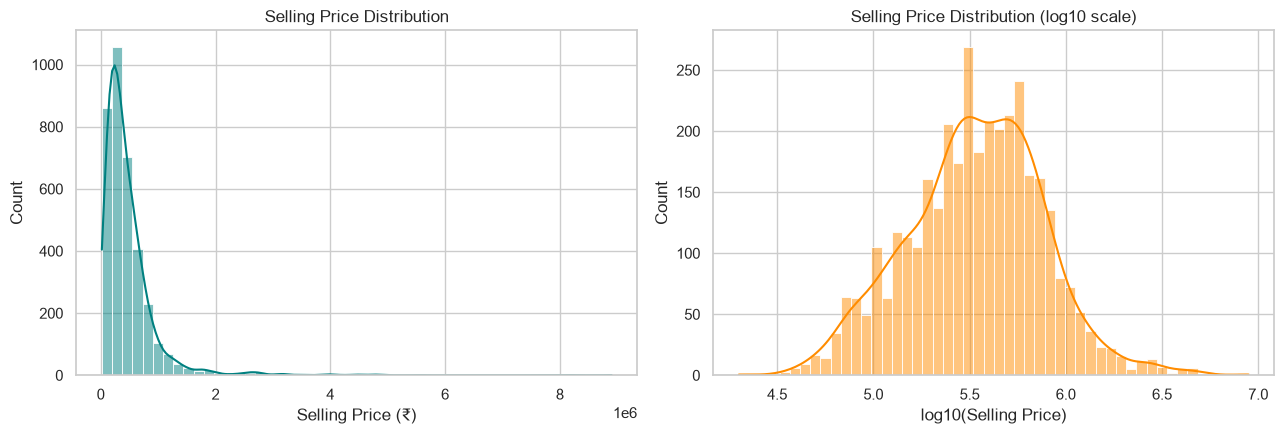

count       3577.0
mean      473913.0
std       509302.0
min        20000.0
25%       200000.0
50%       350000.0
75%       600000.0
max      8900000.0
Name: selling_price, dtype: float64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(df["selling_price"], bins=50, kde=True, color="teal", ax=axes[0])
axes[0].set_title("Selling Price Distribution")
axes[0].set_xlabel("Selling Price (₹)")

sns.histplot(np.log10(df["selling_price"]), bins=50, kde=True, color="darkorange", ax=axes[1])
axes[1].set_title("Selling Price Distribution (log10 scale)")
axes[1].set_xlabel("log10(Selling Price)")

plt.tight_layout()
plt.show()

print(df["selling_price"].describe().round(0))

**Observations:** The price distribution is strongly right-skewed: most used cars sell at relatively low prices and a small number of premium cars sell for much more. The mean is therefore higher than the median. On a log scale the distribution looks much closer to symmetric.

### 5.2 Price vs. fuel type

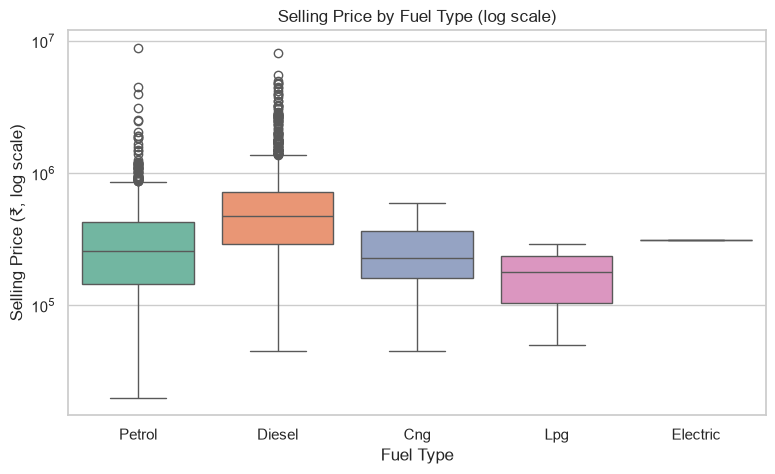

          count    median      mean
fuel                               
Diesel     1800  475000.0  614001.0
Electric      1  310000.0  310000.0
Petrol     1717  260000.0  335344.0
Cng          37  229999.0  273162.0
Lpg          22  180000.0  171818.0


In [7]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="fuel", y="selling_price", hue="fuel", palette="Set2", legend=False)
plt.yscale("log")
plt.title("Selling Price by Fuel Type (log scale)")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price (₹, log scale)")
plt.show()

print(df.groupby("fuel")["selling_price"].agg(["count", "median", "mean"]).round(0).sort_values("median", ascending=False))

**Observations:** Fuel type is clearly linked to price. Diesel cars typically have a higher median price than petrol cars, while LPG and CNG cars are usually cheaper and far less common in the data. The log scale is used so that the differences between groups are visible despite the skew.

### 5.3 Price vs. car age

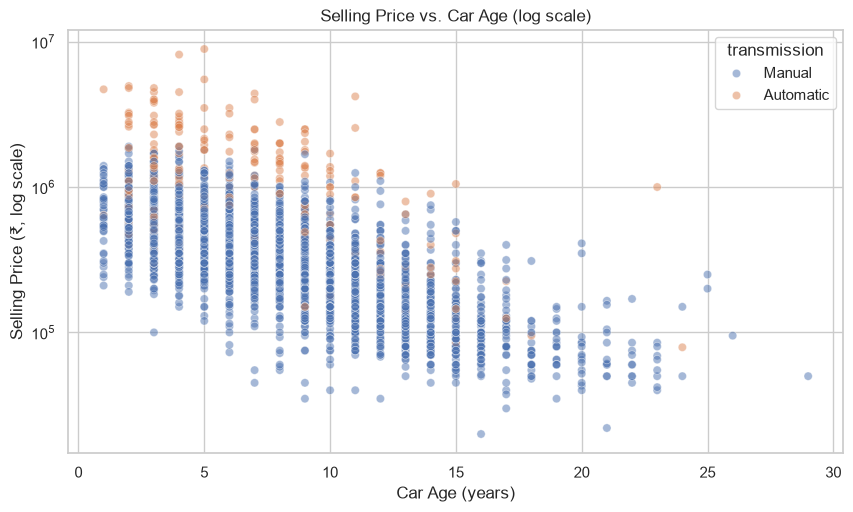

In [8]:
plt.figure(figsize=(10, 5.5))
sns.scatterplot(data=df, x="car_age", y="selling_price", hue="transmission", alpha=0.5)
plt.yscale("log")
plt.title("Selling Price vs. Car Age (log scale)")
plt.xlabel("Car Age (years)")
plt.ylabel("Selling Price (₹, log scale)")
plt.show()

**Observations:** Price falls steadily as a car gets older, which is the expected depreciation pattern. Automatic cars tend to sit above manual cars of the same age. The wide vertical spread at any given age shows that age alone is not enough, and that brand and mileage matter too.

### 5.4 Average price by brand (top 10)

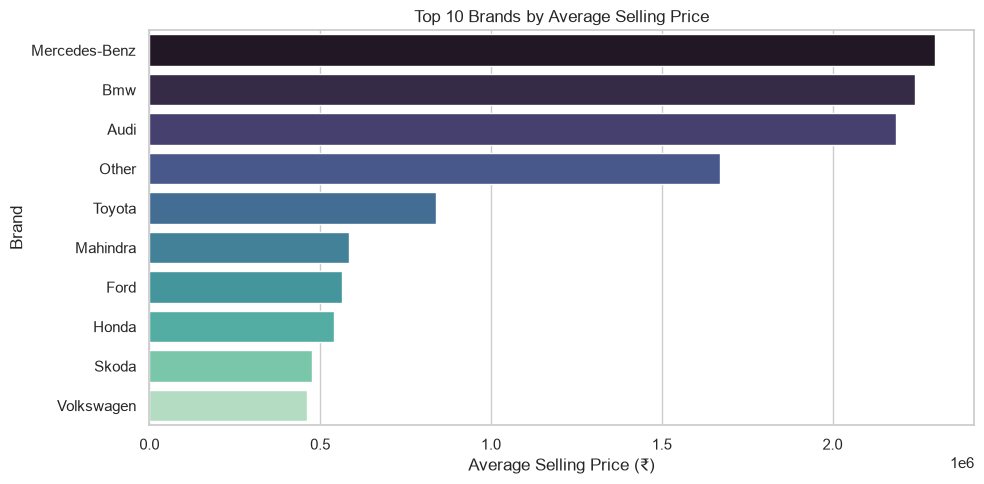

In [9]:
brand_price = df.groupby("brand")["selling_price"].mean().sort_values(ascending=False).head(10).reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=brand_price, x="selling_price", y="brand", hue="brand", palette="mako", legend=False)
plt.title("Top 10 Brands by Average Selling Price")
plt.xlabel("Average Selling Price (₹)")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

**Observations:** Luxury brands command much higher average prices than mass-market brands. This is why brand is a useful feature to extract from the car name.

## 6. Encode Categorical Variables
One-hot encoding turns each category into a 0/1 column. `drop_first=True` removes one redundant column per feature.

In [10]:
model_df = df.drop(columns=["name", "year"])   # 'year' is replaced by 'car_age'; 'name' by 'brand'
cat_features = categorical + ["brand"]
model_df = pd.get_dummies(model_df, columns=cat_features, drop_first=True, dtype=int)

print("Shape after encoding:", model_df.shape)
model_df.head()

Shape after encoding: (3577, 31)


,selling_price,km_driven,car_age,fuel_Diesel,fuel_Electric,fuel_Lpg,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Manual,...,brand_Mahindra,brand_Maruti,brand_Mercedes-Benz,brand_Nissan,brand_Other,brand_Renault,brand_Skoda,brand_Tata,brand_Toyota,brand_Volkswagen
0,60000,70000,14,0,0,0,1,1,0,1,...,0,1,0,0,0,0,0,0,0,0
1,135000,50000,14,0,0,0,1,1,0,1,...,0,1,0,0,0,0,0,0,0,0
2,600000,100000,9,1,0,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
3,250000,46000,4,0,0,0,1,1,0,1,...,0,0,0,0,0,0,0,0,0,0
4,450000,141000,7,1,0,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0


## 7. Feature Correlation Heatmap

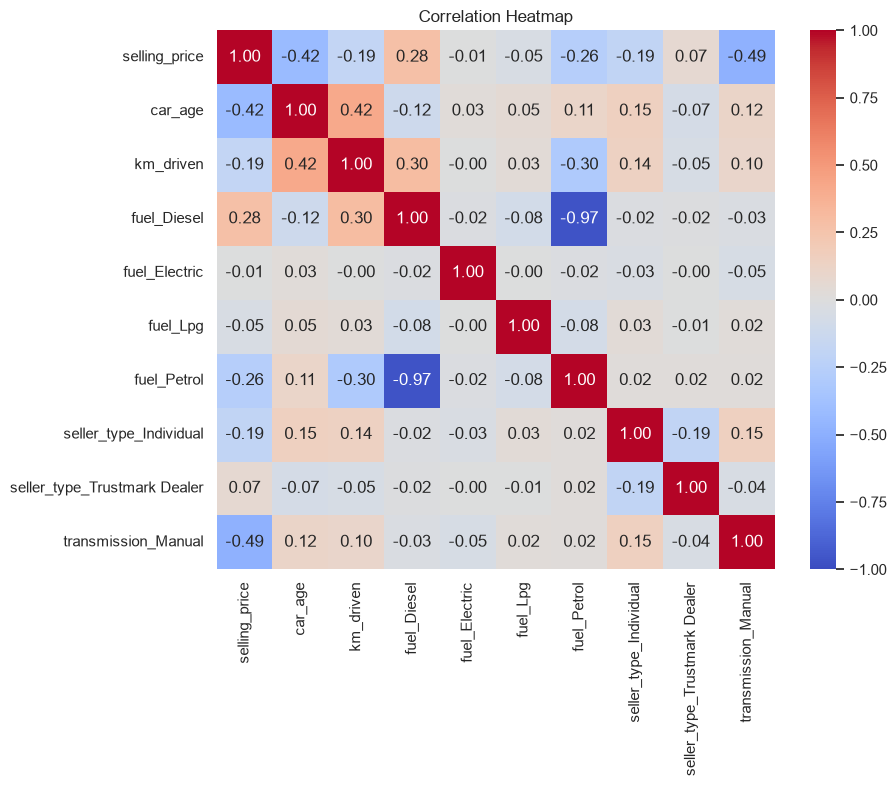

In [11]:
# Brand columns are left out here to keep the heatmap readable
core_cols = ["selling_price", "car_age", "km_driven"] + [
    c for c in model_df.columns if c.startswith(("fuel_", "transmission_", "seller_type_"))
]

plt.figure(figsize=(9, 7))
sns.heatmap(model_df[core_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.show()

**Observations:** Look at the `selling_price` row. Car age normally has a clear negative correlation with price (older cars are cheaper), mileage (`km_driven`) a weaker negative one, and automatic transmission a positive one. Car age and mileage are also correlated with each other, because older cars have usually travelled further. Correlation measures linear relationships only, so the models below can pick up more complex patterns.

## 8. Train/Test Split
An 80/20 split.

In [12]:
X = model_df.drop(columns="selling_price")
y = model_df["selling_price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print("Training samples:", X_train.shape[0])
print("Testing samples: ", X_test.shape[0])
print("Number of features:", X.shape[1])

Training samples: 2861
Testing samples:  716
Number of features: 30


## 9. Train the Regression Models
- **Linear Regression** (baseline, with scaled features)
- **Random Forest Regressor**
- **Gradient Boosting Regressor**

In [13]:
models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    print(f"Trained: {name}")

Trained: Linear Regression
Trained: Random Forest
Trained: Gradient Boosting


## 10. Evaluate the Models
- **MAE** (Mean Absolute Error): the average size of the error, in rupees.
- **RMSE** (Root Mean Squared Error): like MAE but penalises large errors more.
- **R²:** the share of the variation in price that the model explains (1.0 is perfect).

In [14]:
rows = []
for name, pred in predictions.items():
    rows.append({
        "Model": name,
        "MAE (₹)": mean_absolute_error(y_test, pred),
        "RMSE (₹)": np.sqrt(mean_squared_error(y_test, pred)),
        "R²": r2_score(y_test, pred),
    })

results = pd.DataFrame(rows).sort_values("R²", ascending=False).reset_index(drop=True)
best_name = results.loc[0, "Model"]

display_results = results.copy()
display_results["MAE (₹)"] = display_results["MAE (₹)"].round(0).astype(int)
display_results["RMSE (₹)"] = display_results["RMSE (₹)"].round(0).astype(int)
display_results["R²"] = display_results["R²"].round(4)
display_results

,Model,MAE (₹),RMSE (₹),R²
0,Random Forest,165791,379568,0.5528
1,Gradient Boosting,161199,390559,0.5265
2,Linear Regression,186223,392781,0.5211


**Observations:** The table is sorted by R². Linear Regression is a useful baseline, but price depends on non-linear effects (such as depreciation that slows down with age and interactions between brand and age), so tree-based models usually do noticeably better. Compare the three models' MAE, RMSE and R² above, and note which is best.

### Actual vs. predicted prices (best model)

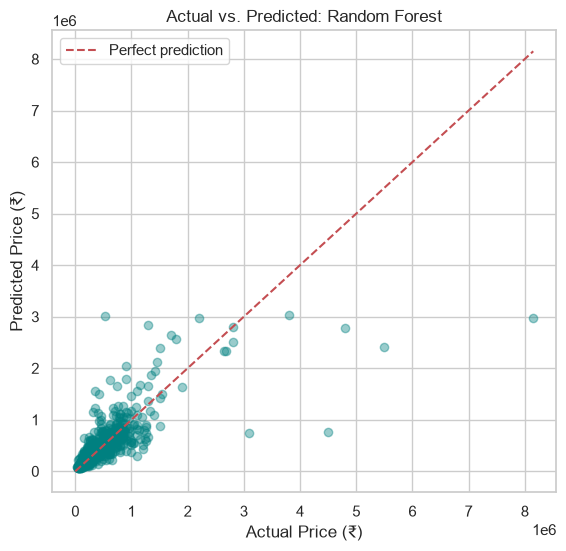

In [15]:
best_pred = predictions[best_name]

plt.figure(figsize=(6.5, 6))
plt.scatter(y_test, best_pred, alpha=0.4, color="teal")
lims = [0, max(y_test.max(), best_pred.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual Price (₹)")
plt.ylabel("Predicted Price (₹)")
plt.title(f"Actual vs. Predicted: {best_name}")
plt.legend()
plt.show()

**Observations:** Points close to the red dashed line are accurate predictions. Errors tend to grow for the most expensive cars, where there are fewer examples to learn from.

## 11. Feature Importance (Best Model)

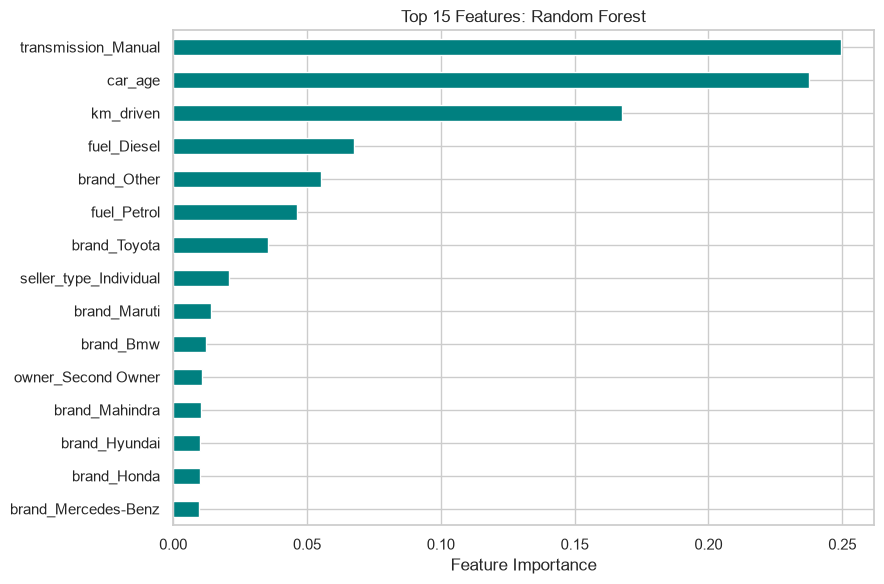

transmission_Manual    0.2494
car_age                0.2376
km_driven              0.1676
fuel_Diesel            0.0676
brand_Other            0.0552
dtype: float64


In [16]:
best_model = models[best_name]

if hasattr(best_model, "feature_importances_"):
    importance = pd.Series(best_model.feature_importances_, index=X.columns)
    label = "Feature Importance"
else:
    # For Linear Regression, use the absolute size of the coefficients (features are scaled)
    importance = pd.Series(np.abs(best_model.named_steps["linearregression"].coef_), index=X.columns)
    label = "|Coefficient| (scaled features)"

top = importance.sort_values(ascending=False).head(15).sort_values()
top.plot(kind="barh", figsize=(9, 6), color="teal")
plt.title(f"Top 15 Features: {best_name}")
plt.xlabel(label)
plt.tight_layout()
plt.show()

print(importance.sort_values(ascending=False).head(5).round(4))

**Observations:** The most important features show what the model relies on most to price a car. Car age and mileage usually rank near the top, followed by transmission, fuel type and premium brands. Features near the bottom (such as rare brands or owner categories) add little.

## 12. Try It: Predict the Price of a Car (Bonus)

In [17]:
def predict_price(name, year, km_driven, fuel, transmission, seller_type="Individual", owner="First Owner"):
    brand = get_brand(name)
    if brand not in set(df["brand"]):
        brand = "Other"

    row = pd.Series(0.0, index=X.columns)
    row["car_age"] = REFERENCE_YEAR - year
    row["km_driven"] = km_driven
    for col in [f"fuel_{fuel}", f"transmission_{transmission}", f"seller_type_{seller_type}",
                f"owner_{owner}", f"brand_{brand}"]:
        if col in row.index:        # the "base" category has no column, which means all zeros
            row[col] = 1.0
    return best_model.predict(row.to_frame().T)[0]

estimate = predict_price("Maruti Swift Dzire VDI", year=2014, km_driven=70000, fuel="Diesel", transmission="Manual")
print(f"Estimated selling price: ₹{estimate:,.0f}")

Estimated selling price: ₹534,200


## 13. Key Numbers (Calculated from the Data)

In [18]:
best = results.iloc[0]
print(f"Cleaned dataset size    : {len(df)} cars")
print(f"Median selling price    : ₹{df['selling_price'].median():,.0f}")
print(f"Best model              : {best_name}")
print(f"  R²                    : {best['R²']:.4f}")
print(f"  MAE                   : ₹{best['MAE (₹)']:,.0f}")
print(f"  RMSE                  : ₹{best['RMSE (₹)']:,.0f}")
print("Top 3 features          :", ", ".join(importance.sort_values(ascending=False).head(3).index))

Cleaned dataset size    : 3577 cars
Median selling price    : ₹350,000
Best model              : Random Forest
  R²                    : 0.5528
  MAE                   : ₹165,791
  RMSE                  : ₹379,568
Top 3 features          : transmission_Manual, car_age, km_driven


## 14. Conclusion

**Summary**
1. **Best model:** Random Forest, with an R² of 0.5528, MAE of ₹165,791 and RMSE of ₹379,568 on the test set (3,577 cars after cleaning; median selling price ₹350,000).
2. **What drives price:** the three most important features were transmission, car age and kilometres driven. This matches intuition: automatic cars and newer, lower-mileage cars sell for higher prices.
3. **Baseline vs. advanced models:** Linear Regression scored R² 0.5211, compared with 0.5528 for Random Forest. 
4. **Model quality:** the model explains a little over half of the price variation. RMSE is much higher than MAE, which indicates a small number of very large errors, mostly on expensive cars, where the data has few examples.

**Limitations and improvements**
- Prices are strongly right-skewed, so predicting `log(price)` would likely reduce errors on expensive cars.
- The dataset has no information on condition, accident history, location or exact model trim, all of which affect price.
- Hyperparameter tuning and cross-validation could improve and stabilise the results.